In [7]:
import numpy as np
import fireducks.pandas as pd

import json
import os
import ijson
import geopandas as gpd
from shapely.geometry import Point
from copy import deepcopy
import sys
import requests
import gzip
from pathlib import Path
from functools import partial

from fastsim import simdrive, vehicle, cycle
from concurrent.futures import ThreadPoolExecutor, as_completed

import matplotlib.pyplot as plt

import geohash2
import folium
from multiprocessing import Pool

import branca.colormap as cm
import matplotlib

ROOT_FOLDER = Path.cwd()

# Ensure src is importable
SRC_PATH = ROOT_FOLDER / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.append(str(SRC_PATH))

# Local imports
from src import utils, access, speed_transform
from src import utils

import importlib


THIS_FILE = os.getcwd()
ROOT_FOLDER = os.path.join(THIS_FILE, '..')

In [34]:
DAY = 1
sc1 = pd.read_csv(f'./data/sc1_day{DAY}_us_og_v8.csv', index_col=0)

sc1 = pd.read_csv(f'./data/sc1_day{DAY}_us_v8.csv', index_col=0)
sc2 = pd.read_csv(f'./data/sc2_day{DAY}_us_v8.csv', index_col=0)

sc1.head()

,perc_fuel_saved,fuel_saving_per_day,fuel_use_frac,num_trips,total_fuel_used,avg_fuel_saved_per_mile,avg_fuel_saved_per_mile_smoothed,state,total_fuel_saved,total_cost_saved,usd_per_gallon,gallons_per_day,avg_fuel_saved_per_100_miles,avg_fuel_saved_per_100_miles_sm
dj3,3.100112,874.494967,0.197899,92347,32060.444806,0.001247,0.001252,alabama,53853.178306,145618.994139,2.704,8.777906e+06,0.124682,0.125212
dj9,2.180240,68.620731,0.039063,16009,6328.335598,0.000838,0.000866,alabama,7475.808409,20214.585938,2.704,8.777906e+06,0.083754,0.086580
djc,2.798024,371.816018,0.077349,31919,12530.850017,0.001149,0.001144,alabama,18997.490812,51369.215157,2.704,8.777906e+06,0.114935,0.114422
djd,2.842219,185.107678,0.055575,25887,9003.384285,0.001076,0.001082,alabama,13865.246796,37491.627337,2.704,8.777906e+06,0.107644,0.108183
dje,2.268560,136.313407,0.051264,23669,8305.063531,0.000892,0.000918,alabama,10208.397940,27603.508030,2.704,8.777906e+06,0.089217,0.091780


In [33]:
sc1_new = sc1.copy(deep=True)
sc1_new = sc1_new[['perc_fuel_saved',
                  'num_trips',
                  'total_fuel_saved',
                  'total_cost_saved',
                  'avg_fuel_saved_per_100_miles']]

sc1_new['total_fuel_saved_mil_gal'] = sc1_new['total_fuel_saved'] / 1000000
sc1_new['total_cost_saved_mil_usd'] = sc1_new['total_cost_saved'] / 1000000


sc1_new.rename(columns={'perc_fuel_saved': '% Fuel Saved',
                       'num_trips': 'Number of Trips',
                       'total_fuel_saved_mil_gal': 'Total Fuel Saved (Million Gallons)',
                       'total_cost_saved_mil_usd': 'Total Cost Saved (Million USD)',
                       'avg_fuel_saved_per_100_miles': 'Avg. Fuel Saved per 100 VMT'}, inplace=True)

sc1_new.drop(columns=['total_fuel_saved',
                     'total_cost_saved'], inplace=True)

sc1_new = sc1_new[['% Fuel Saved',
                  'Number of Trips',
                  'Total Fuel Saved (Million Gallons)',
                  'Total Cost Saved (Million USD)',
                  'Avg. Fuel Saved per 100 VMT']]
sc1_new.index.name = 'Geohash'
sc1_new.sort_values(by='Total Fuel Saved (Million Gallons)', ascending=False, inplace=True)
sc1_new.to_csv(f'./data/icev_day{DAY}_sc1_new.csv')

In [35]:
sc2_new = sc2.copy(deep=True)
sc2_new = sc2_new[['perc_fuel_saved',
                  'num_trips',
                  'total_fuel_saved',
                  'total_cost_saved',
                  'avg_fuel_saved_per_100_miles']]

sc2_new['total_fuel_saved_mil_gal'] = sc2_new['total_fuel_saved'] / 1000000
sc2_new['total_cost_saved_mil_usd'] = sc2_new['total_cost_saved'] / 1000000


sc2_new.rename(columns={'perc_fuel_saved': '% Fuel Saved',
                       'num_trips': 'Number of Trips',
                       'total_fuel_saved_mil_gal': 'Total Fuel Saved (Million Gallons)',
                       'total_cost_saved_mil_usd': 'Total Cost Saved (Million USD)',
                       'avg_fuel_saved_per_100_miles': 'Avg. Fuel Saved per 100 VMT'}, inplace=True)

sc2_new.drop(columns=['total_fuel_saved',
                     'total_cost_saved'], inplace=True)

sc2_new = sc2_new[['% Fuel Saved',
                  'Number of Trips',
                  'Total Fuel Saved (Million Gallons)',
                  'Total Cost Saved (Million USD)',
                  'Avg. Fuel Saved per 100 VMT']]
sc2_new.index.name = 'Geohash'
sc2_new.sort_values(by='Total Fuel Saved (Million Gallons)', ascending=False, inplace=True)
sc2_new.to_csv(f'./data/icev_day{DAY}_sc2.csv')

In [55]:
len(sc1.index), len(sc2.index), len(set(list(sc1.index) +  list(sc2.index)))

(518, 518, 518)

In [68]:
sc1['save_diff'] = (sc2['avg_fuel_saved_per_100_miles'] - sc1['avg_fuel_saved_per_100_miles']) / sc1['avg_fuel_saved_per_100_miles'] * 100 
sc1['save_diff'] = sc1['save_diff'].replace([np.inf, -np.inf], 0, inplace=False)

sc2['save_diff'] = (sc2['avg_fuel_saved_per_100_miles'] - sc1['avg_fuel_saved_per_100_miles']) / sc1['avg_fuel_saved_per_100_miles'] * 100 
sc2['save_diff'] = sc1['save_diff'].replace([np.inf, -np.inf], 0, inplace=False)


# sc1['save_diff'].max()
sc1 = sc1.fillna(value=0)

sc2 = sc2.fillna(value=0)
sc1['sc2_sav'] = sc2['avg_fuel_saved_per_100_miles']
sc2['sc1_sav'] = sc1['avg_fuel_saved_per_100_miles']

# sc1[['num_trips', 'save_diff']]

In [69]:
sc1.loc[(sc1['state']!='alaska') & (sc1['num_trips'] > 5000)].sort_values(by='save_diff')

,perc_fuel_saved,fuel_saving_per_day,fuel_use_frac,num_trips,total_fuel_used,avg_fuel_saved_per_mile,avg_fuel_saved_per_mile_smoothed,state,total_fuel_saved,total_cost_saved,usd_per_gallon,gallons_per_day,avg_fuel_saved_per_100_miles,avg_fuel_saved_per_100_miles_sm,save_diff,sc2_sav
9qm,4.756818,128.818555,0.005561,13648,3429.161053,0.001766,0.001606,california,9153.919358,33906.117303,3.704,3.460192e+07,0.176588,0.160612,2.021823,0.180159
87z,2.638707,252.016412,0.651529,35669,11427.648654,0.001298,0.001298,hawaii,19619.543003,72670.787284,3.704,1.141206e+06,0.129775,0.129771,7.752769,0.139836
dp4,4.209481,2236.749053,0.426964,235420,75235.545467,0.001474,0.001460,indiana,137044.248269,383449.806656,2.798,7.625013e+06,0.147429,0.145972,8.708219,0.160267
dp3,4.354345,6035.961931,0.593608,592388,175009.040276,0.001490,0.001486,illinois,280177.224861,783935.875161,2.798,1.083953e+07,0.148995,0.148586,8.761935,0.162050
9q8,3.976294,155.831106,0.009439,22834,5819.778113,0.001753,0.001742,california,12986.364227,48101.493096,3.704,3.460192e+07,0.175265,0.174235,9.548671,0.192000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
dq6,1.985138,21.141258,0.007450,5417,1665.443433,0.000740,0.000741,north carolina,1986.201885,5871.212772,2.956,1.342972e+07,0.074044,0.074125,59.592877,0.118170
9tc,2.018729,49.800877,0.015171,11698,2987.429572,0.000743,0.000754,arizona,2472.262238,9157.259329,3.704,8.072555e+06,0.074335,0.075364,60.527333,0.119328
9rw,0.867161,13.879360,0.134525,9471,3199.218238,0.000336,0.000371,idaho,3087.800607,8624.227096,2.793,2.646949e+06,0.033560,0.037089,66.312768,0.055815
f0h,1.398600,15.214900,0.004494,7050,1795.407629,0.000510,0.000529,michigan,665.011021,1860.700837,2.798,1.057970e+07,0.051027,0.052882,66.960607,0.085194


In [70]:
sc2.loc[(sc2['state']!='alaska') & (sc2['num_trips'] > 5000)].sort_values(by='save_diff')

,perc_fuel_saved,fuel_saving_per_day,fuel_use_frac,num_trips,total_fuel_used,avg_fuel_saved_per_mile,avg_fuel_saved_per_mile_smoothed,state,total_fuel_saved,total_cost_saved,usd_per_gallon,gallons_per_day,avg_fuel_saved_per_100_miles,avg_fuel_saved_per_100_miles_sm,save_diff,sc1_sav
9qm,4.813505,135.842275,0.005561,13648,3429.161053,0.001802,0.001681,california,9263.005378,34310.171921,3.704,3.460192e+07,0.180159,0.168107,2.021823,0.176588
87z,2.883590,271.763666,0.651529,35669,11427.648654,0.001398,0.001398,hawaii,21440.319290,79414.942649,3.704,1.141206e+06,0.139836,0.139831,7.752769,0.129775
dp4,4.542541,2524.076189,0.426964,235420,75235.545467,0.001603,0.001591,indiana,147887.371483,413788.865410,2.798,7.625013e+06,0.160267,0.159080,8.708219,0.147429
dp3,4.705052,6949.010595,0.593608,592388,175009.040276,0.001620,0.001617,illinois,302743.190623,847075.447362,2.798,1.083953e+07,0.162050,0.161683,8.761935,0.148995
9q8,4.348963,174.556476,0.009439,22834,5819.778113,0.001920,0.001938,california,14203.480703,52609.692523,3.704,3.460192e+07,0.192000,0.193829,9.548671,0.175265
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
dq6,3.145599,39.121069,0.007450,5417,1665.443433,0.001182,0.001182,north carolina,3147.284725,9303.373648,2.956,1.342972e+07,0.118170,0.118250,59.592877,0.074044
9tc,3.206896,74.269874,0.015171,11698,2987.429572,0.001193,0.001194,arizona,3927.367231,14546.968224,3.704,8.072555e+06,0.119328,0.119407,60.527333,0.074335
9rw,1.416323,22.178776,0.134525,9471,3199.218238,0.000558,0.000599,idaho,5043.266637,14085.843717,2.793,2.646949e+06,0.055815,0.059940,66.312768,0.033560
f0h,2.317052,24.838042,0.004494,7050,1795.407629,0.000852,0.000851,michigan,1101.719146,3082.610169,2.798,1.057970e+07,0.085194,0.085126,66.960607,0.051027


In [4]:
df1 = pd.read_csv('./data/sc1_day1_us_og.csv', index_col=0)
df2 = pd.read_csv('./data/sc1_day2_us_og.csv', index_col=0)
df3 = pd.read_csv('./data/sc1_day3_us_og.csv', index_col=0)
df4 = pd.read_csv('./data/sc1_day4_us_og.csv', index_col=0)

mn = df1.loc[df1['state']=='minnesota']
mn['total_fuel_saved'].sum(), mn['total_cost_saved'].sum()

(188491.24670454202, 527398.5082793087)

In [13]:
mn = df1.loc[df1['state']=='minnesota']
mn['total_fuel_saved'].sum(), mn['total_cost_saved'].sum(), mn['total_fuel_saved'].sum() * 8887 / 1000000

(188491.24670454202, 527398.5082793087, 1675.121709463265)

In [14]:
mn = df2.loc[df2['state']=='minnesota']
mn['total_fuel_saved'].sum(), mn['total_cost_saved'].sum(), mn['total_fuel_saved'].sum() * 8887 / 1000000

(230348.19301357638, 777194.8032278067, 2047.1043913116534)

In [15]:
mn = df3.loc[df3['state']=='minnesota']
mn['total_fuel_saved'].sum(), mn['total_cost_saved'].sum(), mn['total_fuel_saved'].sum() * 8887 / 1000000

(271072.59956994304, 885323.1101954337, 2409.0221923780837)

In [16]:
mn = df4.loc[df4['state']=='minnesota']
mn['total_fuel_saved'].sum(), mn['total_cost_saved'].sum(), mn['total_fuel_saved'].sum() * 8887 / 1000000

(249043.25516521707, 738911.3380751989, 2213.247408653284)

In [19]:
(527398.5082793087 + 777194.8032278067 + 885323.1101954337 + 738911.3380751989)/4*365

267255533.0797195

In [11]:
np.mean([df_.loc[df_['state']=='minnesota']['total_fuel_saved'].sum() for df_ in (df1, df2, df3, df4)])*365

85679670.61886166

In [17]:
np.mean([df_.loc[df_['state']=='minnesota']['total_cost_saved'].sum() for df_ in (df1, df2, df3, df4)])*365

267255533.0797195

In [18]:
np.mean([df_.loc[df_['state']=='minnesota']['total_fuel_saved'].sum() for df_ in (df1, df2, df3, df4)])*365 * 8887 / 1000000

761435.2327898236

In [11]:
mn

,perc_fuel_saved,fuel_saving_per_day,fuel_use_frac,num_trips,avg_fuel_saved_per_mile,avg_fuel_saved_per_mile_smoothed,state,total_fuel_saved,total_cost_saved,usd_per_gallon,gallons_per_day,avg_fuel_saved_per_100_miles
cbw,2.093974,3.674561,0.001217,810,0.000836,0.000836,minnesota,170.672370,477.541290,2.798,6695815.4,0.083638
cbe,2.266053,32.690369,0.013066,6734,0.000965,0.000978,minnesota,1982.462569,5546.930267,2.798,6695815.4,0.096540
cbh,3.565246,378.135643,0.064432,32764,0.001433,0.001473,minnesota,15381.343905,43037.000245,2.798,6695815.4,0.143290
cbm,2.515790,79.466870,0.022920,10503,0.001022,0.001090,minnesota,3860.884119,10802.753765,2.798,6695815.4,0.102250
cb7,3.596838,285.329004,0.064612,37373,0.001461,0.001453,minnesota,15561.050914,43539.820457,2.798,6695815.4,0.146083
cbx,1.192820,0.017830,0.000018,17,0.000554,0.000794,minnesota,1.429629,4.000101,2.798,6695815.4,0.055418
cbs,3.462569,22.611046,0.003769,1689,0.001378,0.001252,minnesota,873.926374,2445.245994,2.798,6695815.4,0.137818
cbj,4.119570,1840.320413,0.277479,138927,0.001622,0.001618,minnesota,76539.376929,214157.176647,2.798,6695815.4,0.162238
9zu,3.180850,141.935346,0.032004,18831,0.001232,0.001372,minnesota,6816.436865,19072.390348,2.798,6695815.4,0.123195
cbt,4.203316,4.924558,0.000519,209,0.001879,0.001631,minnesota,146.194961,409.053501,2.798,6695815.4,0.187860


In [8]:
mn

,perc_fuel_saved,fuel_saving_per_day,fuel_use_frac,num_trips,avg_fuel_saved_per_mile,avg_fuel_saved_per_mile_smoothed,state,total_fuel_saved,total_cost_saved,usd_per_gallon,gallons_per_day,avg_fuel_saved_per_100_miles
cbw,2.471991,2.858764,0.001217,810,0.000901,0.000898,minnesota,201.483179,563.749936,2.798,6695815.4,0.090060
cbe,2.512261,23.132480,0.013066,6734,0.000996,0.001003,minnesota,2197.858370,6149.607718,2.798,6695815.4,0.099555
cbh,2.586294,222.026030,0.064432,32764,0.000972,0.001012,minnesota,11157.904550,31219.816932,2.798,6695815.4,0.097237
cbm,2.196739,58.073750,0.022920,10503,0.000824,0.000850,minnesota,3371.249393,9432.755801,2.798,6695815.4,0.082443
cb7,2.982441,244.410303,0.064612,37373,0.001167,0.001157,minnesota,12902.975975,36102.526778,2.798,6695815.4,0.116724
cbx,0.000000,0.000000,0.000018,17,0.000000,0.000766,minnesota,0.000000,0.000000,2.798,6695815.4,0.000000
cbs,3.236047,16.818041,0.003769,1689,0.001249,0.001170,minnesota,816.753978,2285.277632,2.798,6695815.4,0.124869
cbj,3.035045,1296.902153,0.277479,138927,0.001127,0.001123,minnesota,56389.487256,157777.785342,2.798,6695815.4,0.112675
9zu,2.384471,99.106679,0.032004,18831,0.000871,0.000962,minnesota,5109.827943,14297.298584,2.798,6695815.4,0.087120
cbt,3.593719,3.764467,0.000519,209,0.001400,0.001325,minnesota,124.992642,349.729413,2.798,6695815.4,0.140005


In [3]:
# Plotting Options
# Plot Options
# plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams.update({'font.size': 16})
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['savefig.pad_inches'] = 0.5
plt.rcParams['axes.titlepad'] = 6.0
plt.rcParams['axes.labelpad'] = 2.0
plt.rcParams['figure.figsize'] = [16,8]
plt.rcParams['figure.dpi'] = 160
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['scatter.edgecolors'] = 'face'
plt.rcParams['figure.facecolor'] = 'white'  # background of the figure

# matplotlib.rcParams.update(matplotlib.rcParamsDefault)

plt.rcParams.update({
    # Font and padding
    'font.size': 16,
    'axes.titlepad': 6.0,
    'axes.labelpad': 6.0,  # slightly more breathing room

    # Figure properties
    'figure.dpi': 300,
    'figure.facecolor': 'white',

    # Axes (plot area)
    'axes.facecolor': 'white',
    'axes.edgecolor': 'black',
    'axes.linewidth': 1.0,
    'axes.grid': True,  

    # Ticks
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.size': 5,
    'xtick.minor.size': 3,
    'ytick.major.size': 5,
    'ytick.minor.size': 3,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,

    # Tick appearance
    'xtick.top': True,
    'ytick.right': True,

    # Legends
    'legend.fontsize': 14,
    'legend.frameon': True,  # cleaner look

    # Savefig
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1,

    # Lines
    'lines.linewidth': 2.0,
    'lines.markersize': 6,

    # Scatter
    'scatter.edgecolors': 'face'
})

In [6]:
which_data = {'day': 2,
             'geo': '9zv',
             'hour': 0}
data = access.load_data(which_data)

In [8]:
trip_list.append({'day': which_data['day'],
                 'geo': which_data['geo'],
                 'hour': which_data['hour'],
                 'jid': jid})

trip_list_save = os.path.join('.', 'data', 'trip_list.json')
with open(trip_list_save, 'w') as wf:
    json.dump(trip_list, wf)

In [7]:
jid_list = []
num_j = len(data)
for i, jid in enumerate(data.keys()):
    if len(data[jid]['Time']) > 750 and len(data[jid]['Time']) < 780:
        traj = access.Trajectory.from_dict(data[jid])
        if (45.0 in traj.speed_limit_mph) and (60.0 in traj.speed_limit_mph) and (30.0 in traj.speed_limit_mph):
            jid_list.append(jid)
    print(f'{i}/{num_j}', end='\r')

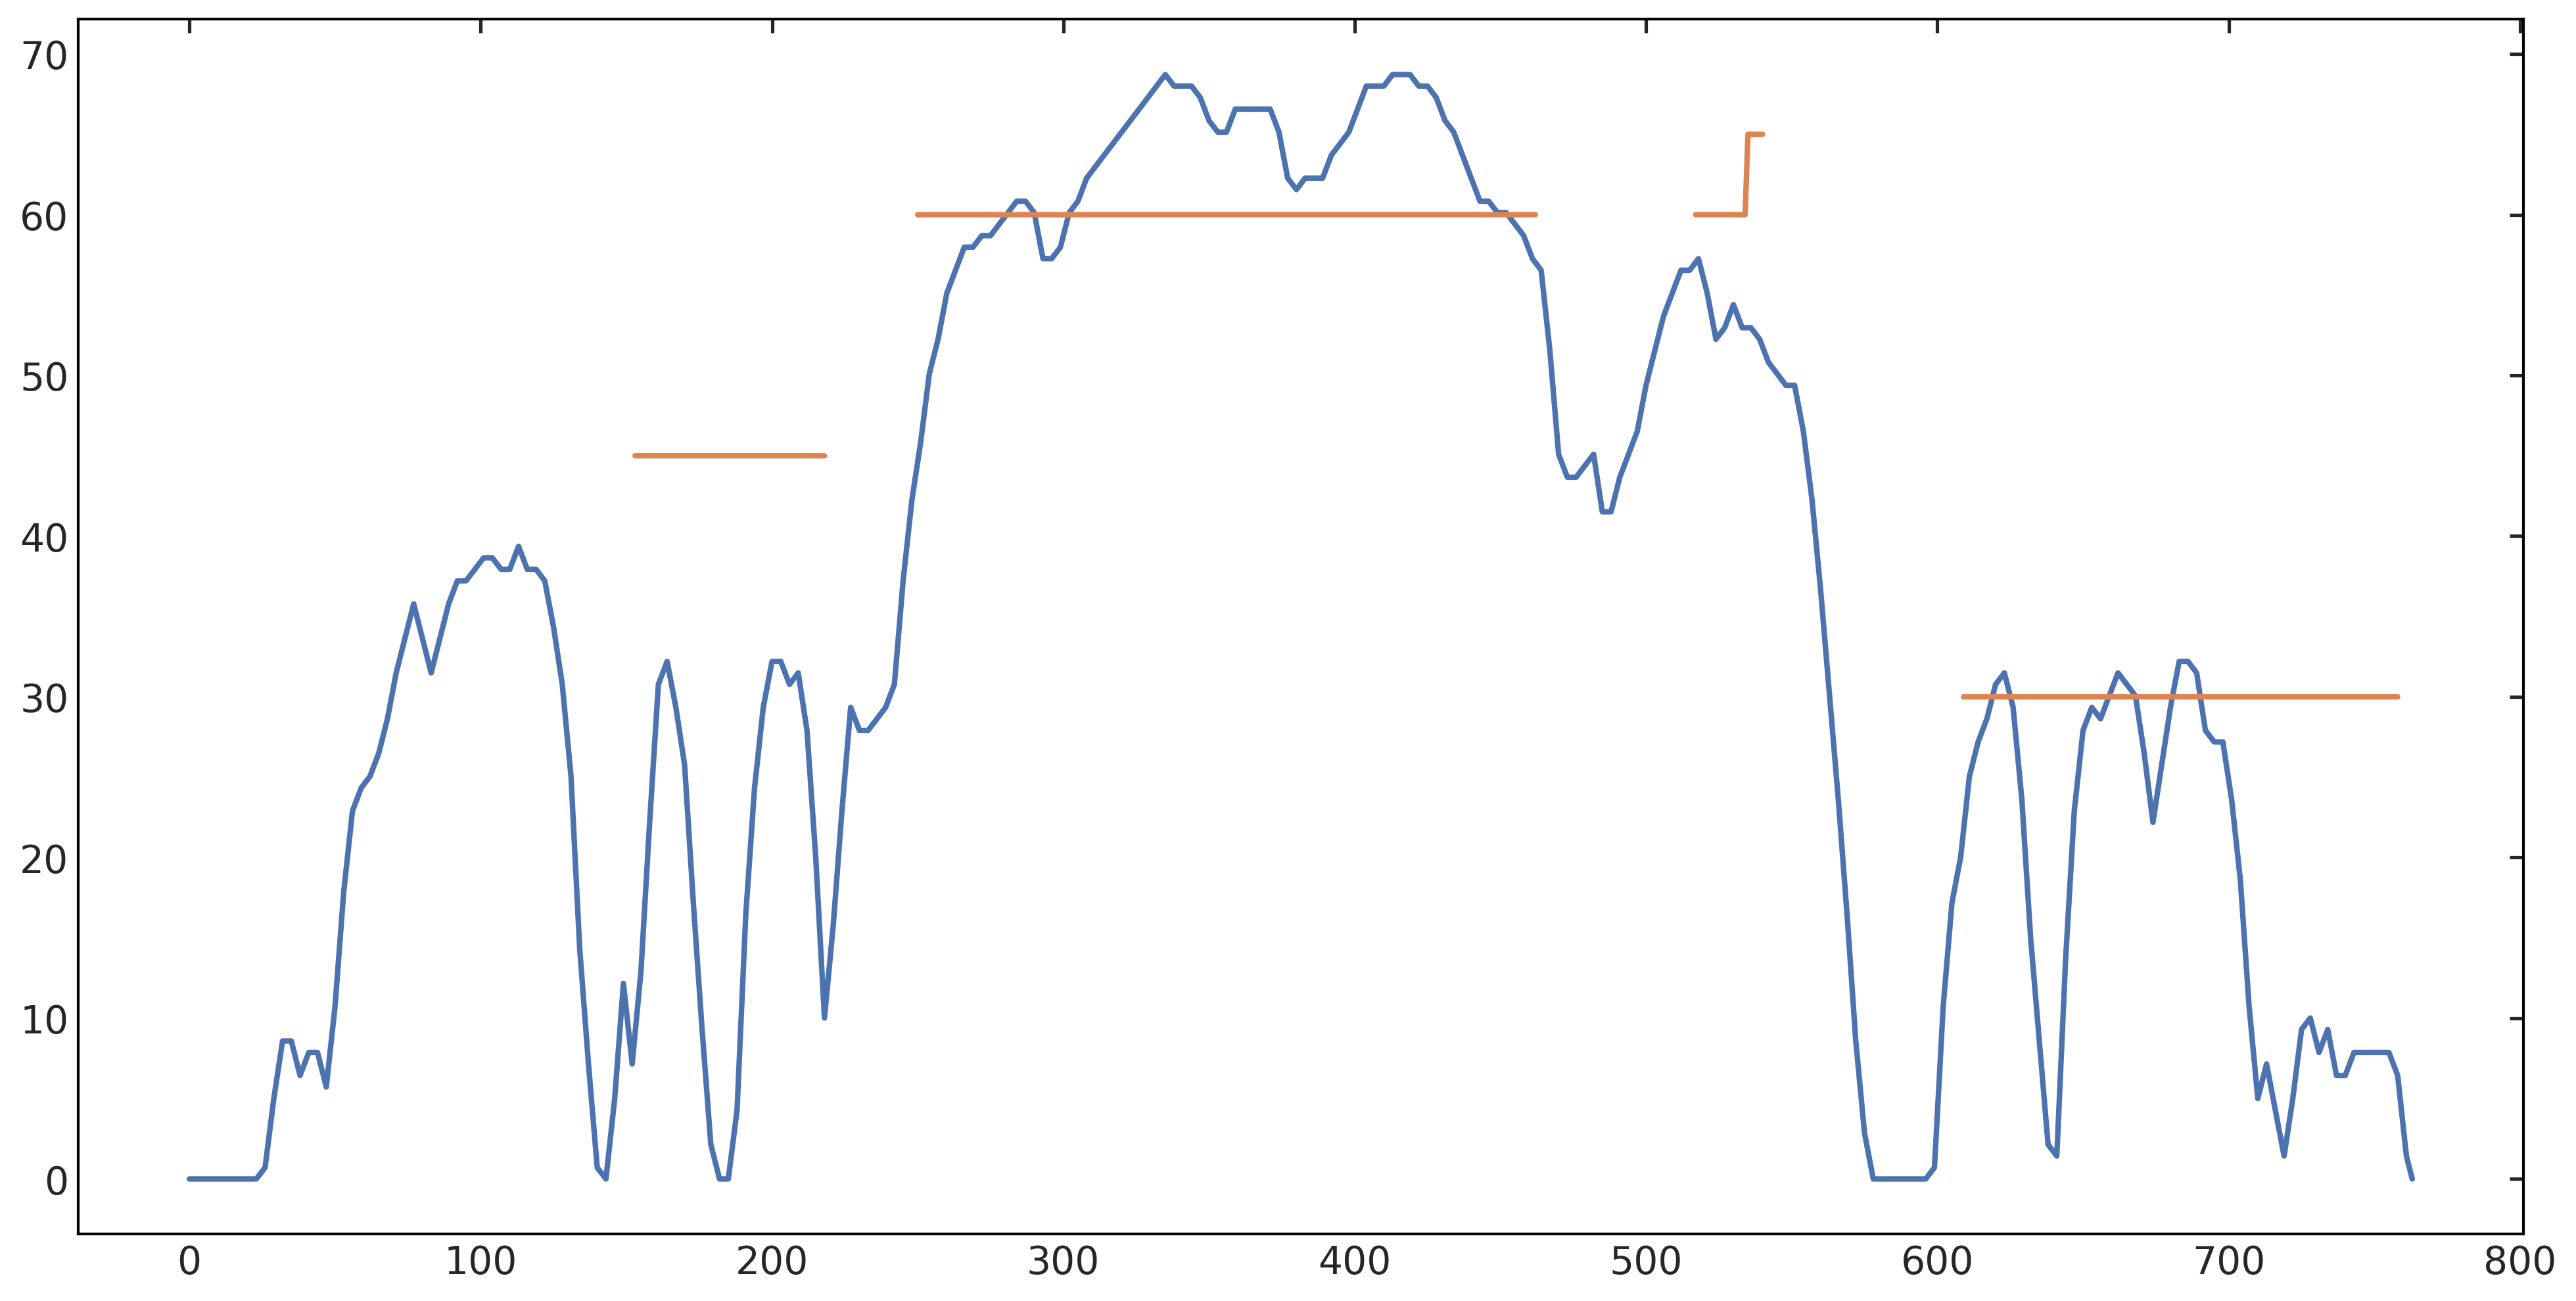

In [7]:
geo = which_data['geo']
state_max_sl = utils.get_state_max_sl(geo)
if state_max_sl is None:
    state_max_sl = 70
    
# jid = list(data.keys())[49]
jid = jid_list[0]
traj_og = access.Trajectory.from_dict(data[jid])

plt.plot(traj_og.speed_mph)
plt.plot(traj_og.speed_limit_mph)

In [13]:
geo = which_data['geo']
state_max_sl = utils.get_state_max_sl(geo)
if state_max_sl is None:
    state_max_sl = 70
    
# jid = list(data.keys())[49]
jid = jid_list[0]
traj_og = access.Trajectory.from_dict(data[jid])
traj_og.speed_mph = np.array(traj_og.speed_mph)
traj_og.speed_limit_mph = np.array(traj_og.speed_limit_mph)
traj_og.time_s = np.array(traj_og.time_s)
adjusted_speeds, adjusted_seconds,  adjusted_speed_limit = speed_transform.adjust_speeds_without_coasting_numba_new(traj_og.speed_mph, traj_og.time_s, traj_og.speed_limit_mph)
# adjusted_speeds, adjusted_seconds,  adjusted_speed_limit = speed_transform.adjust_speeds_with_coasting_numba(traj_og.speed_mph, traj_og.time_s, traj_og.speed_limit_mph)


adjusted_speeds = np.array(adjusted_speeds)
adjusted_seconds = np.array(adjusted_seconds)
adjusted_speed_limit = np.array(adjusted_speed_limit)


final1_speeds, final1_seconds, final1_speed_limit = speed_transform.apply_accel_limit_numba3(adjusted_speeds, adjusted_seconds, adjusted_speed_limit,
                                                                                             limit_accel=np.array([1]*len(adjusted_speeds)), max_accel=2)
final1_speeds, final1_seconds, final1_speed_limit  = speed_transform.remove_duplicates(final1_speeds, final1_seconds, final1_speed_limit)
adjusted_speeds = adjusted_speeds.tolist()
adjusted_seconds = adjusted_seconds.tolist()
adjusted_speed_limit = adjusted_speed_limit.tolist()

dist_list = speed_transform.distance_travelled(traj_og.speed_mph, traj_og.time_s)
adjusted_dist_list = speed_transform.distance_travelled(adjusted_speeds, adjusted_seconds)
final1_dist_list = speed_transform.distance_travelled(final1_speeds, final1_seconds)

adjusted_elevation = speed_transform.adjust_elevation(traj_og.elevation_m, dist_list, adjusted_dist_list)
final1_elevation = speed_transform.adjust_elevation(traj_og.elevation_m, dist_list, final1_dist_list)
    
traj_adj = access.TrajectoryModified.from_dict({'Seconds': adjusted_seconds, 'Speed': adjusted_speeds, 'SpeedLimit': adjusted_speed_limit, 'Elevation': adjusted_elevation})
traj_final1 = access.TrajectoryModified.from_dict({'Seconds': final1_seconds, 'Speed': final1_speeds, 'SpeedLimit': final1_speed_limit, 'Elevation': final1_elevation})



# plt.plot(traj.speed_mph)
# plt.plot(traj.speed_limit_mph)

In [14]:
analysis_og = access.TrajectoryAnalysis(traj_og, epa_class='Large Cars', pt_type='ICEV')
sim_drive_post_og = analysis_og.get_simdrive_post()

analysis_adj = access.TrajectoryAnalysis(traj_adj, epa_class='Large Cars', pt_type='ICEV')
sim_drive_post_adj = analysis_adj.get_simdrive_post()

analysis_final = access.TrajectoryAnalysis(traj_final1, epa_class='Large Cars', pt_type='ICEV')
sim_drive_post_final = analysis_final.get_simdrive_post()

2025-10-20 16:48:15.768 | simdrive.py:2272 | WARNING: trace miss distance fraction 0.00121 exceeds tolerance of 0.001
2025-10-20 16:48:15.769 | simdrive.py:2290 | WARNING: trace miss speed 2.44099 m/s exceeds tolerance of 1.0 m/s
2025-10-20 16:48:15.848 | simdrive.py:2290 | WARNING: trace miss speed 2.1453 m/s exceeds tolerance of 1.0 m/s
2025-10-20 16:48:15.931 | simdrive.py:2290 | WARNING: trace miss speed 1.74525 m/s exceeds tolerance of 1.0 m/s


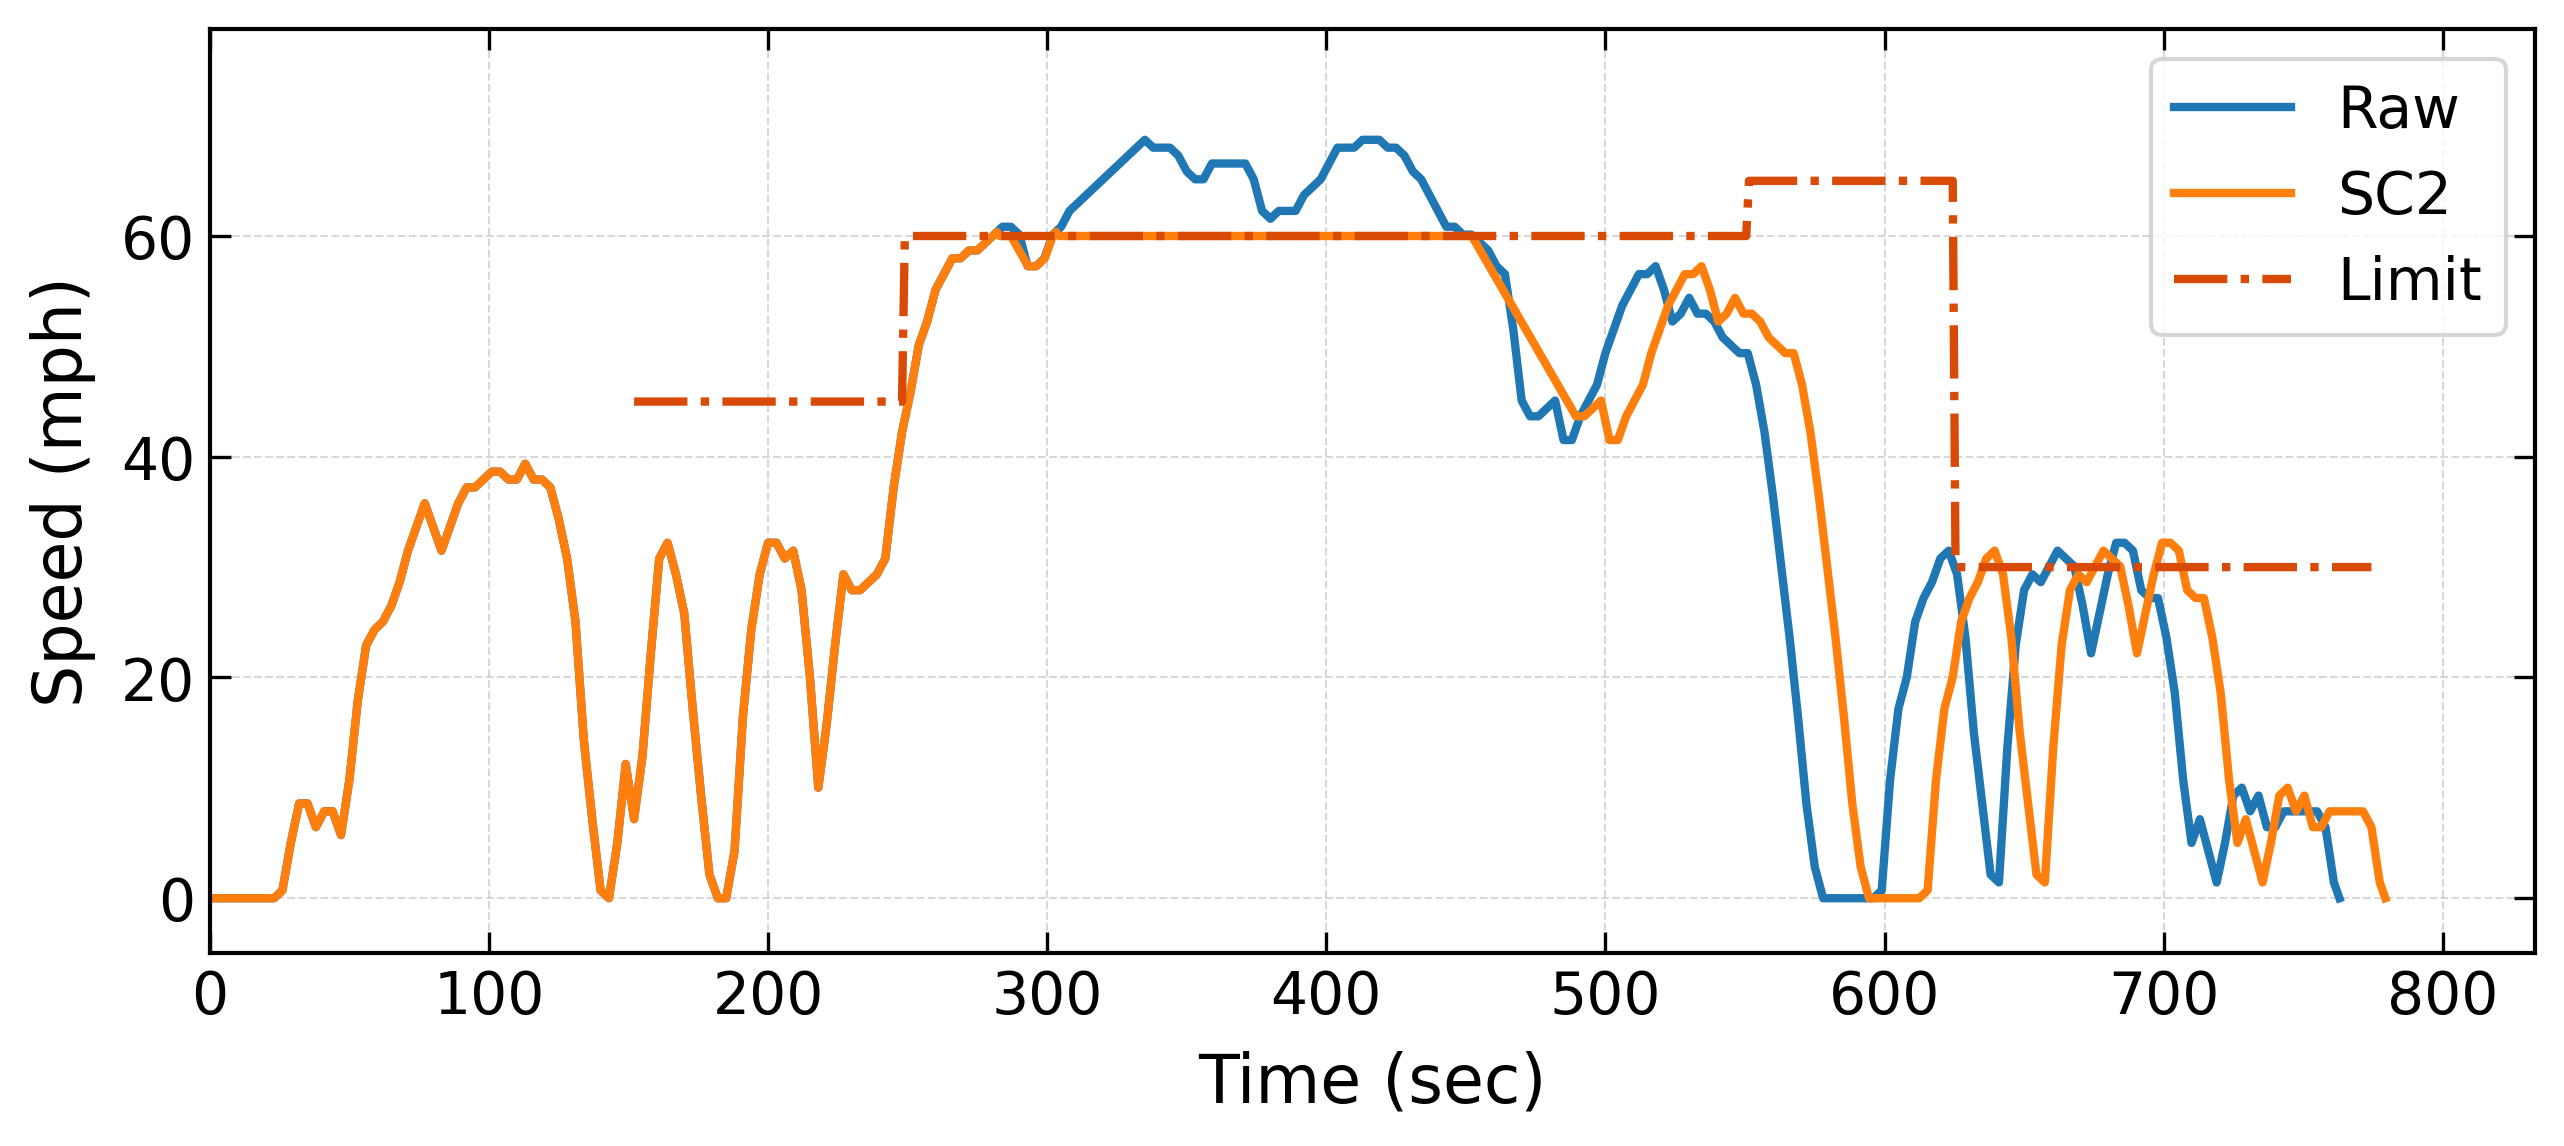

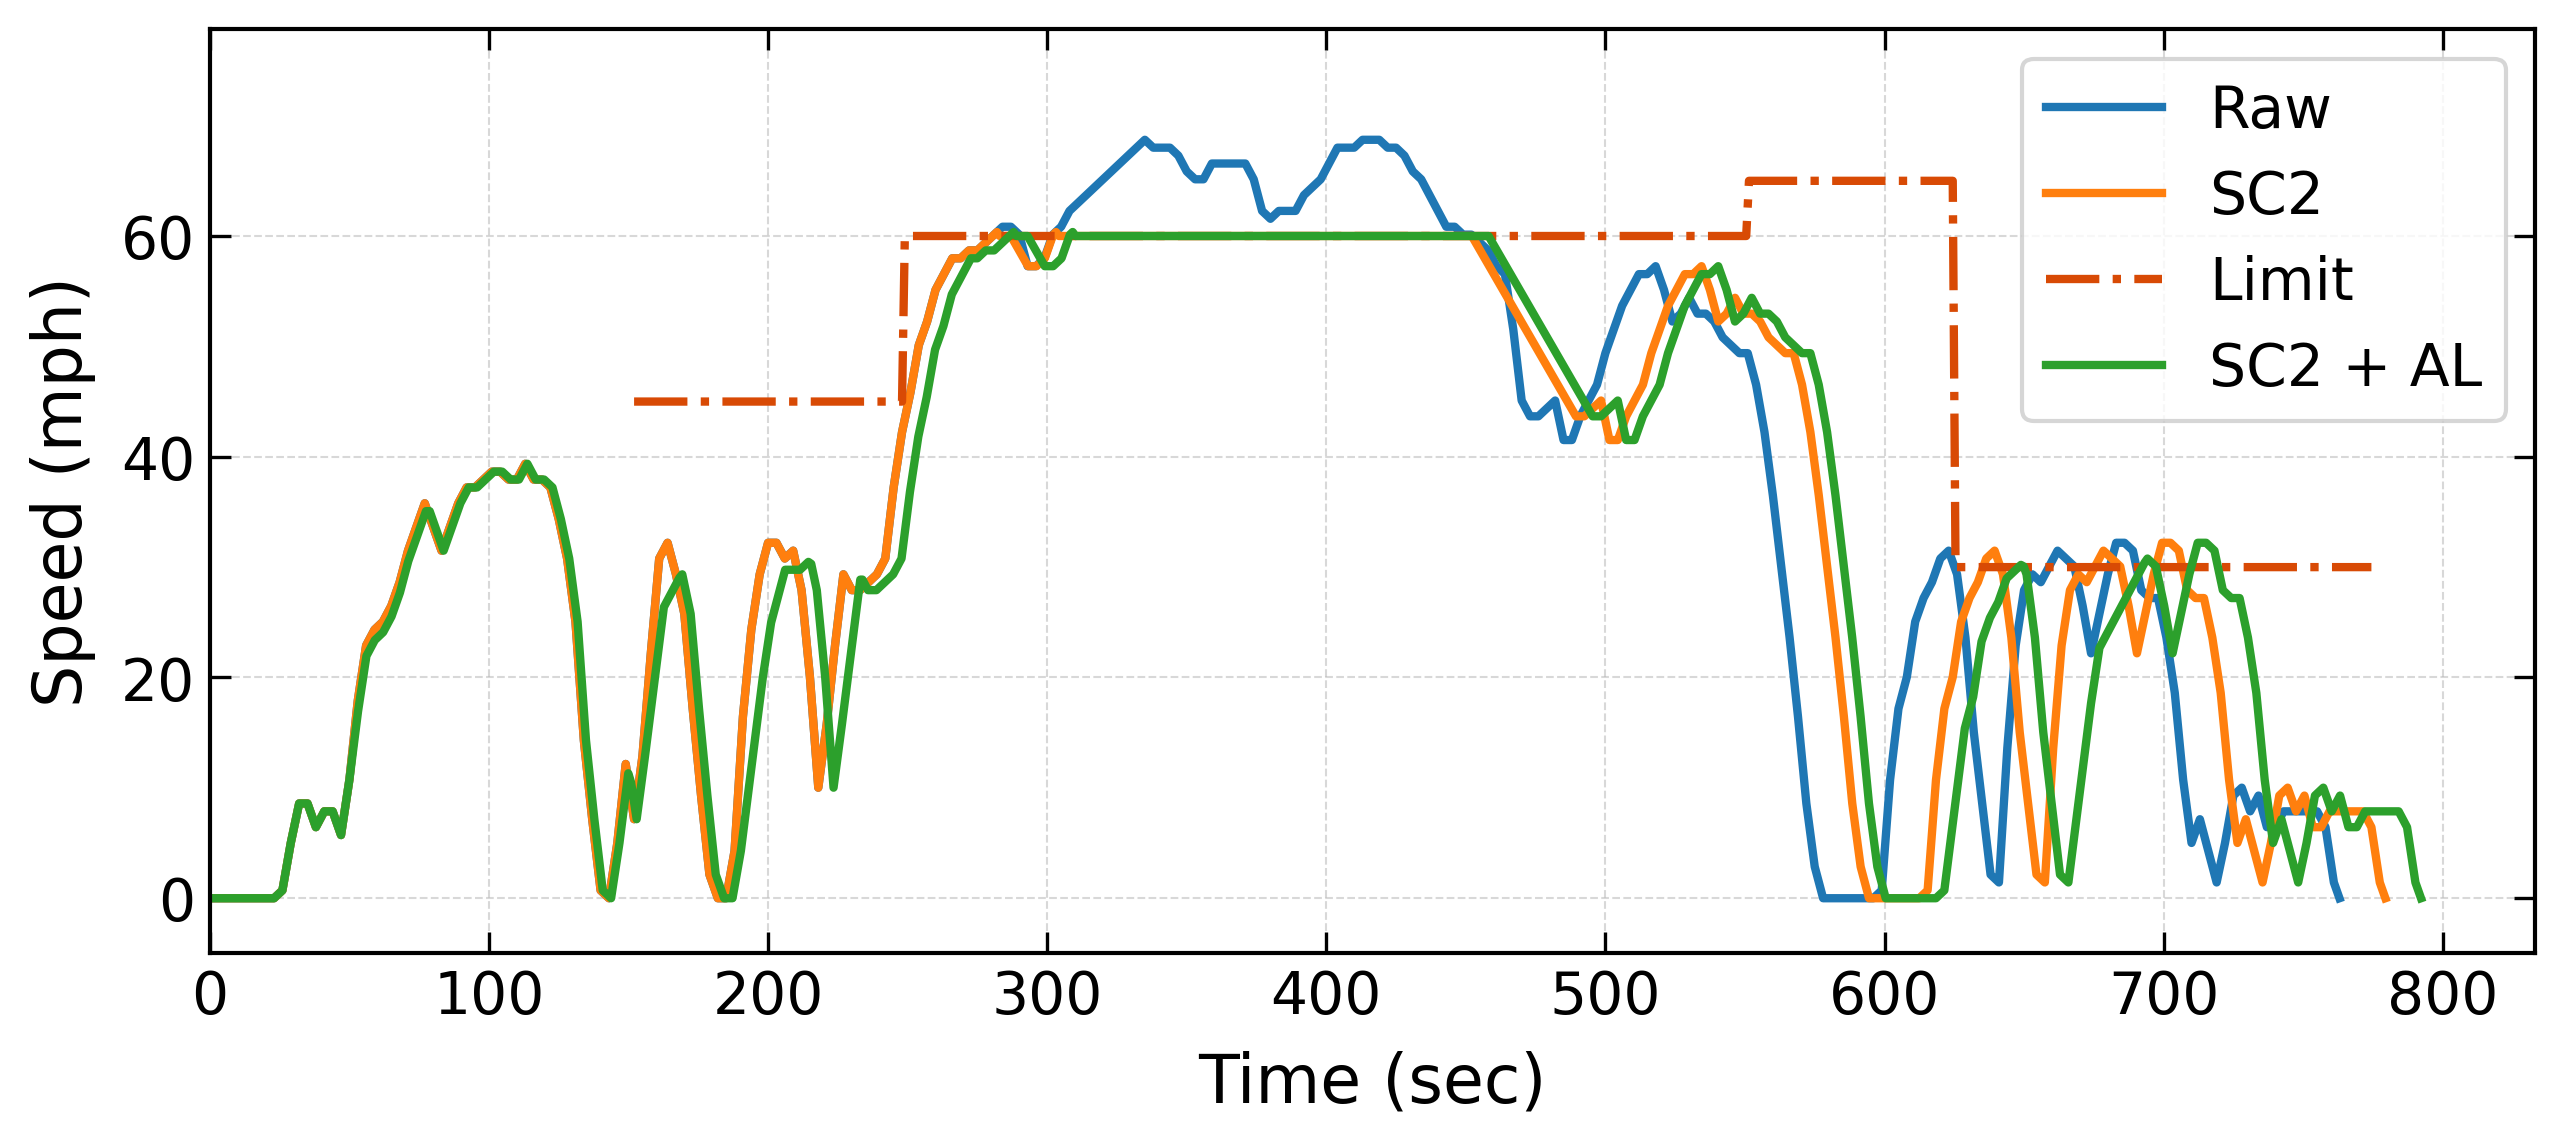

In [68]:
# start = 150
# end = 197
start = 0
end = len(traj_final1.speed_mph)

plt.figure(figsize=[10,4])

p = plt.plot(traj_og.time_s, [speed*1 for speed in traj_og.speed_mph], label='Raw')

# plt.plot(traj_adj.time_s, traj_adj.speed_mph, color='green',label='SC2')
p = plt.plot(traj_adj.time_s, traj_adj.speed_mph, label='SC2')

# plt.plot(traj_final1.time_s, traj_final1.speed_mph, label='SC1 + AC')
# plt.plot(traj_adj2.time_s, traj_adj2.speed_mph, label='Compliant (old coasting)')
plt.plot(traj_adj.time_s, traj_adj.speed_limit_mph, '-.', color='#D84A05', label='Limit')
plt.xlabel('Time (sec)')
plt.ylabel('Speed (mph)')

plt.legend(loc='upper right')
plt.xlim((start, end))
plt.ylim((min([speed*1-5 for speed in traj_og.speed_mph]), max([speed*1+10 for speed in traj_og.speed_mph])))
plt.grid(True, which='major', axis='both', color='#b3b3b3', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.show()
plt.savefig(f'./figures/og_vs_adj_coast.png')
plt.show()




plt.figure(figsize=[10,4])

p = plt.plot(traj_og.time_s, [speed*1 for speed in traj_og.speed_mph], label='Raw')

# plt.plot(traj_adj.time_s, traj_adj.speed_mph, color='green',label='SC2')
p = plt.plot(traj_adj.time_s, traj_adj.speed_mph, label='SC2')

# plt.plot(traj_final1.time_s, traj_final1.speed_mph, label='SC1 + AC')
# plt.plot(traj_adj2.time_s, traj_adj2.speed_mph, label='Compliant (old coasting)')
plt.plot(traj_adj.time_s, traj_adj.speed_limit_mph, '-.', color='#D84A05', label='Limit')
plt.plot(traj_final1.time_s, traj_final1.speed_mph, label='SC2 + AL')

plt.xlabel('Time (sec)')
plt.ylabel('Speed (mph)')

plt.legend(loc='upper right')
plt.xlim((start, end))
plt.ylim((min([speed*1-5 for speed in traj_og.speed_mph]), max([speed*1+10 for speed in traj_og.speed_mph])))
plt.grid(True, which='major', axis='both', color='#b3b3b3', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.show()
plt.savefig(f'./figures/adj_vs_final_coast.png')
plt.show()


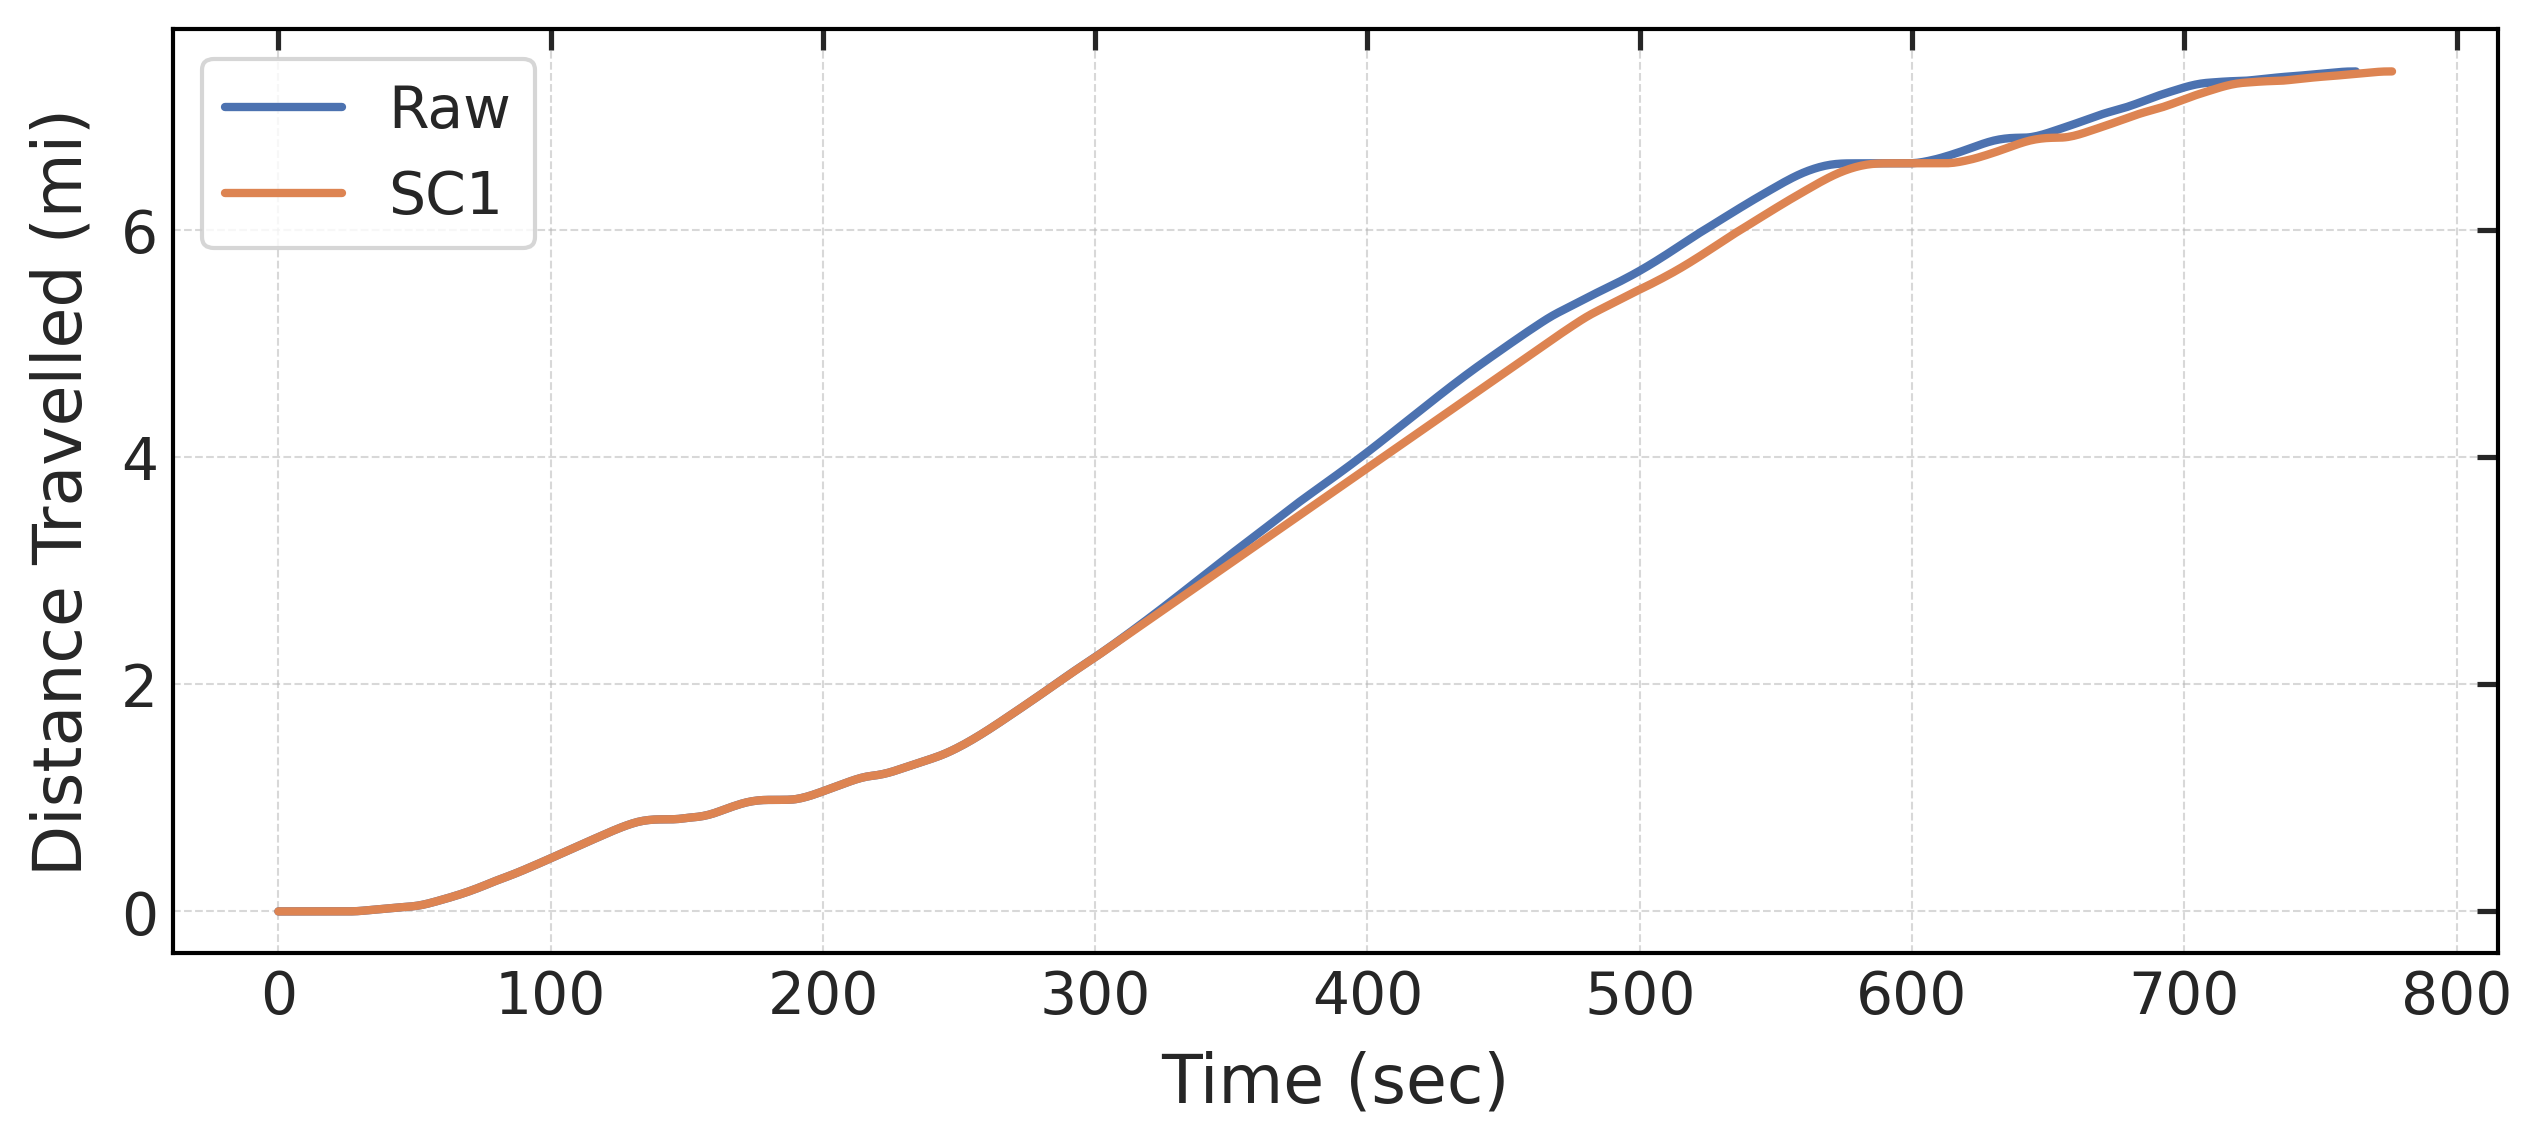

Original Distance: 7.3960060542159605
Distance after adjustment 1: 7.39631807354821
Distance after adjustment 2: 7.395970770926228


In [15]:
plt.figure(figsize=(10,4))
plt.plot(traj_og.time_s, dist_list, label='Raw')
# plt.plot(traj_adj.time_s, adjusted_dist_list, color='green', label='SC2')
plt.plot(traj_adj.time_s, adjusted_dist_list, label='SC1')
# plt.plot(traj_adj2.time_s, adjusted_dist_list2, color='red', label='Speed Limit Adjusted Speed 2')
# plt.plot(traj_final1.time_s, final1_dist_list, label='SC2 + AL')

plt.xlabel('Time (sec)')
plt.ylabel('Distance Travelled (mi)')
plt.grid(True, which='major', axis='both', color='#b3b3b3', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.grid()
plt.legend()
plt.savefig('./figures/og_vs_adj_vs_final_dist_new.png')
plt.show()


print(f'Original Distance: {dist_list[-1]}\nDistance after adjustment 1: {adjusted_dist_list[-1]}\nDistance after adjustment 2: {final1_dist_list[-1]}')

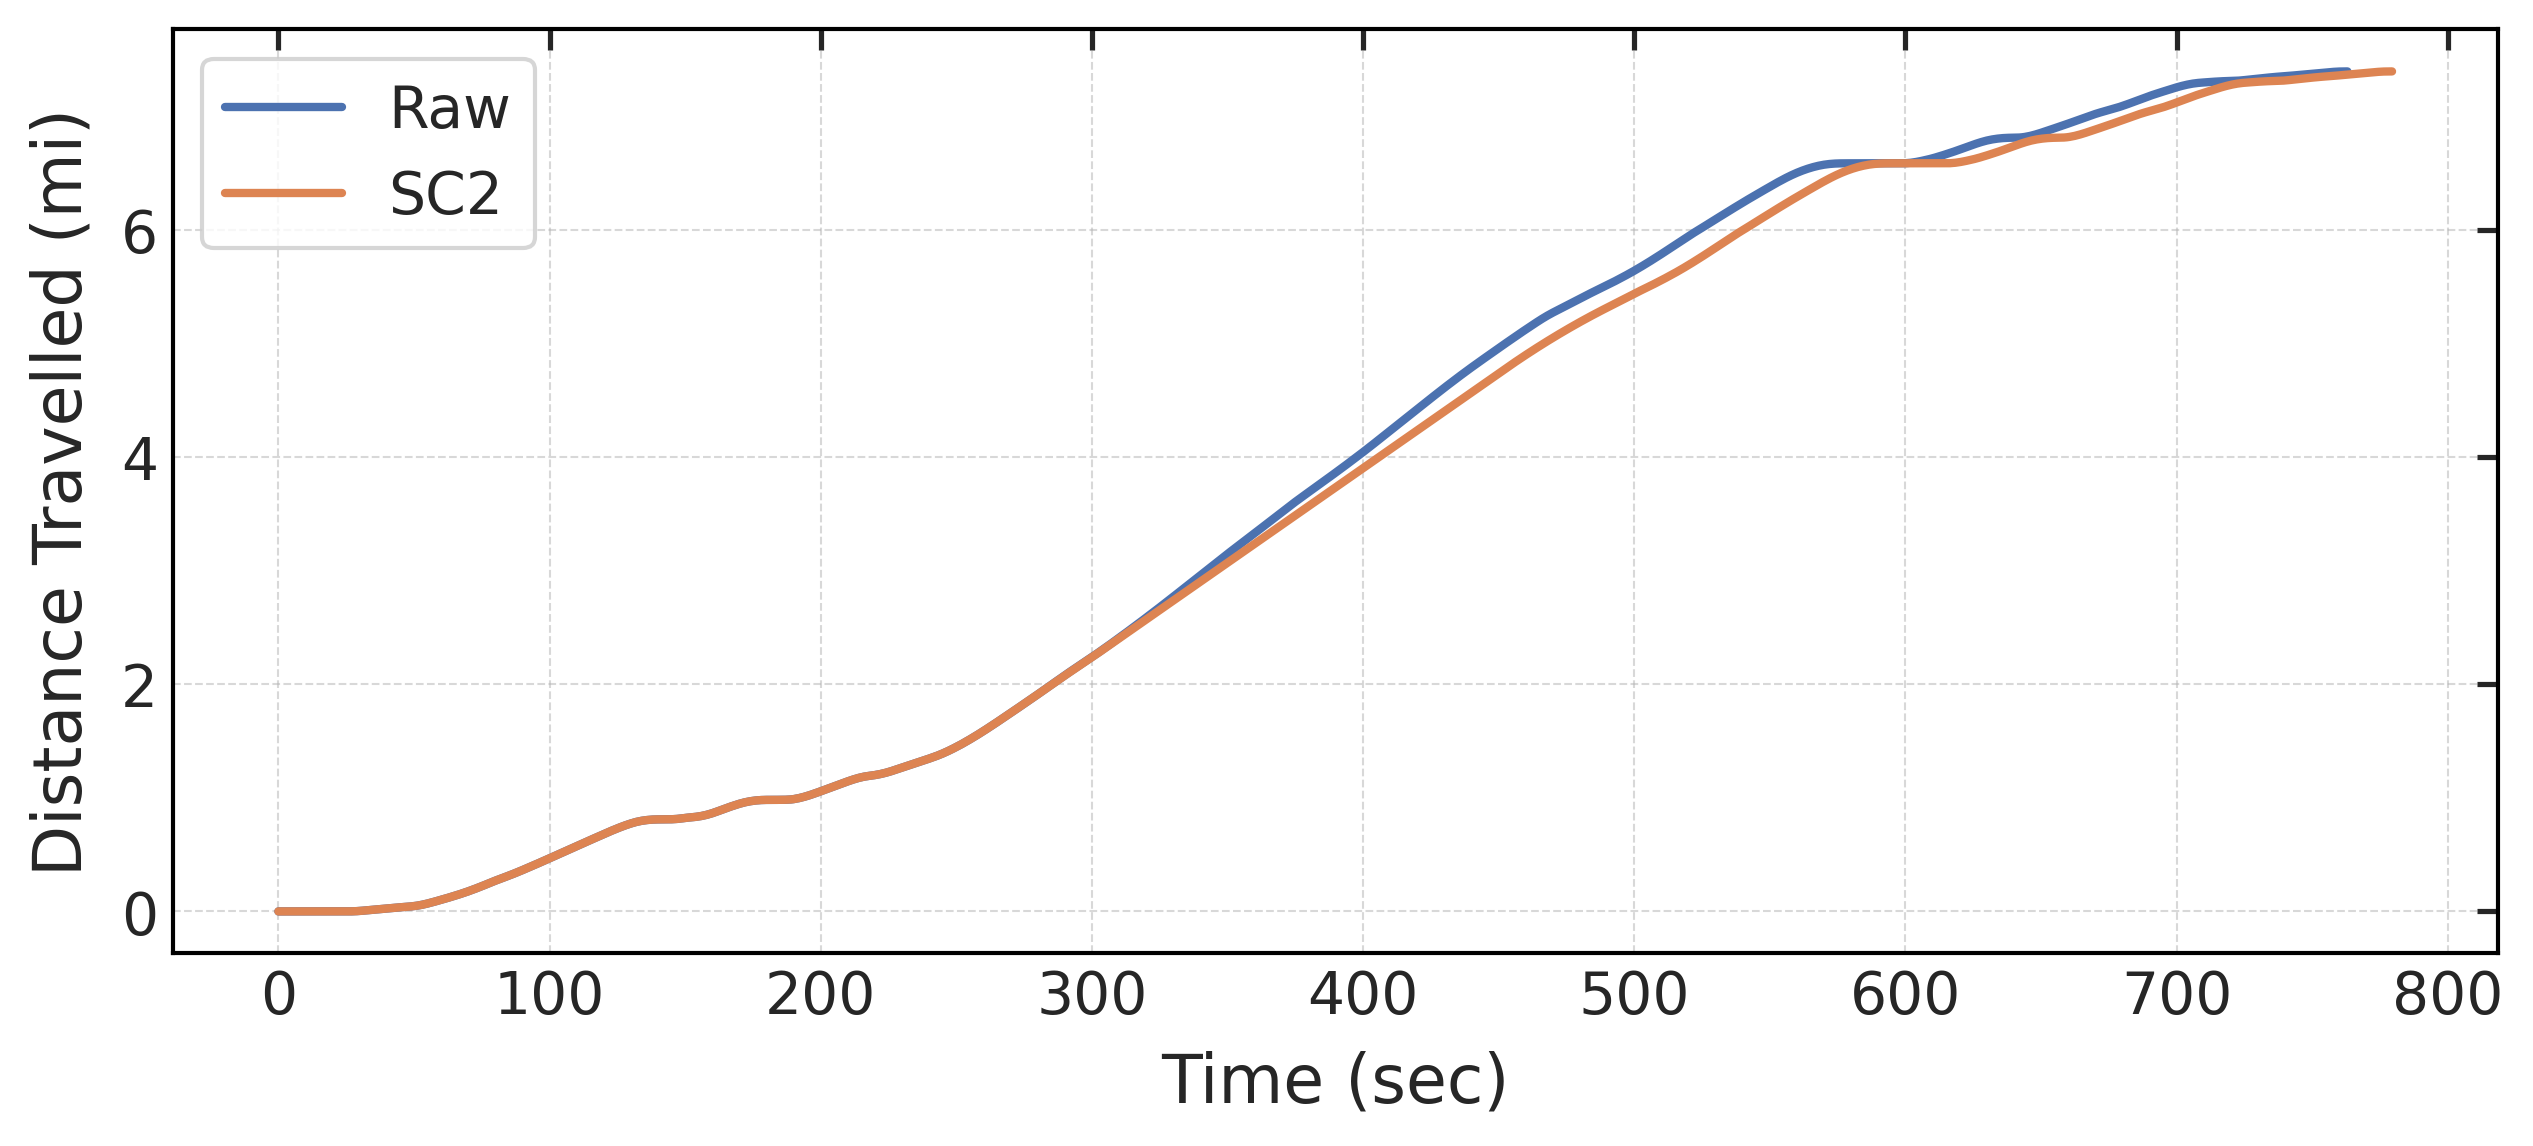

Original Distance: 7.3960060542159605
Distance after adjustment 1: 7.396006054215943
Distance after adjustment 2: 7.3956587515939605


In [12]:
plt.figure(figsize=(10,4))
plt.plot(traj_og.time_s, dist_list, label='Raw')
# plt.plot(traj_adj.time_s, adjusted_dist_list, color='green', label='SC2')
plt.plot(traj_adj.time_s, adjusted_dist_list, label='SC1')
# plt.plot(traj_adj2.time_s, adjusted_dist_list2, color='red', label='Speed Limit Adjusted Speed 2')
# plt.plot(traj_final1.time_s, final1_dist_list, label='SC2 + AL')

plt.xlabel('Time (sec)')
plt.ylabel('Distance Travelled (mi)')
plt.grid(True, which='major', axis='both', color='#b3b3b3', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.grid()
plt.legend()
plt.savefig('./figures/og_vs_adj_vs_final_dist_new.png')
plt.show()


print(f'Original Distance: {dist_list[-1]}\nDistance after adjustment 1: {adjusted_dist_list[-1]}\nDistance after adjustment 2: {final1_dist_list[-1]}')

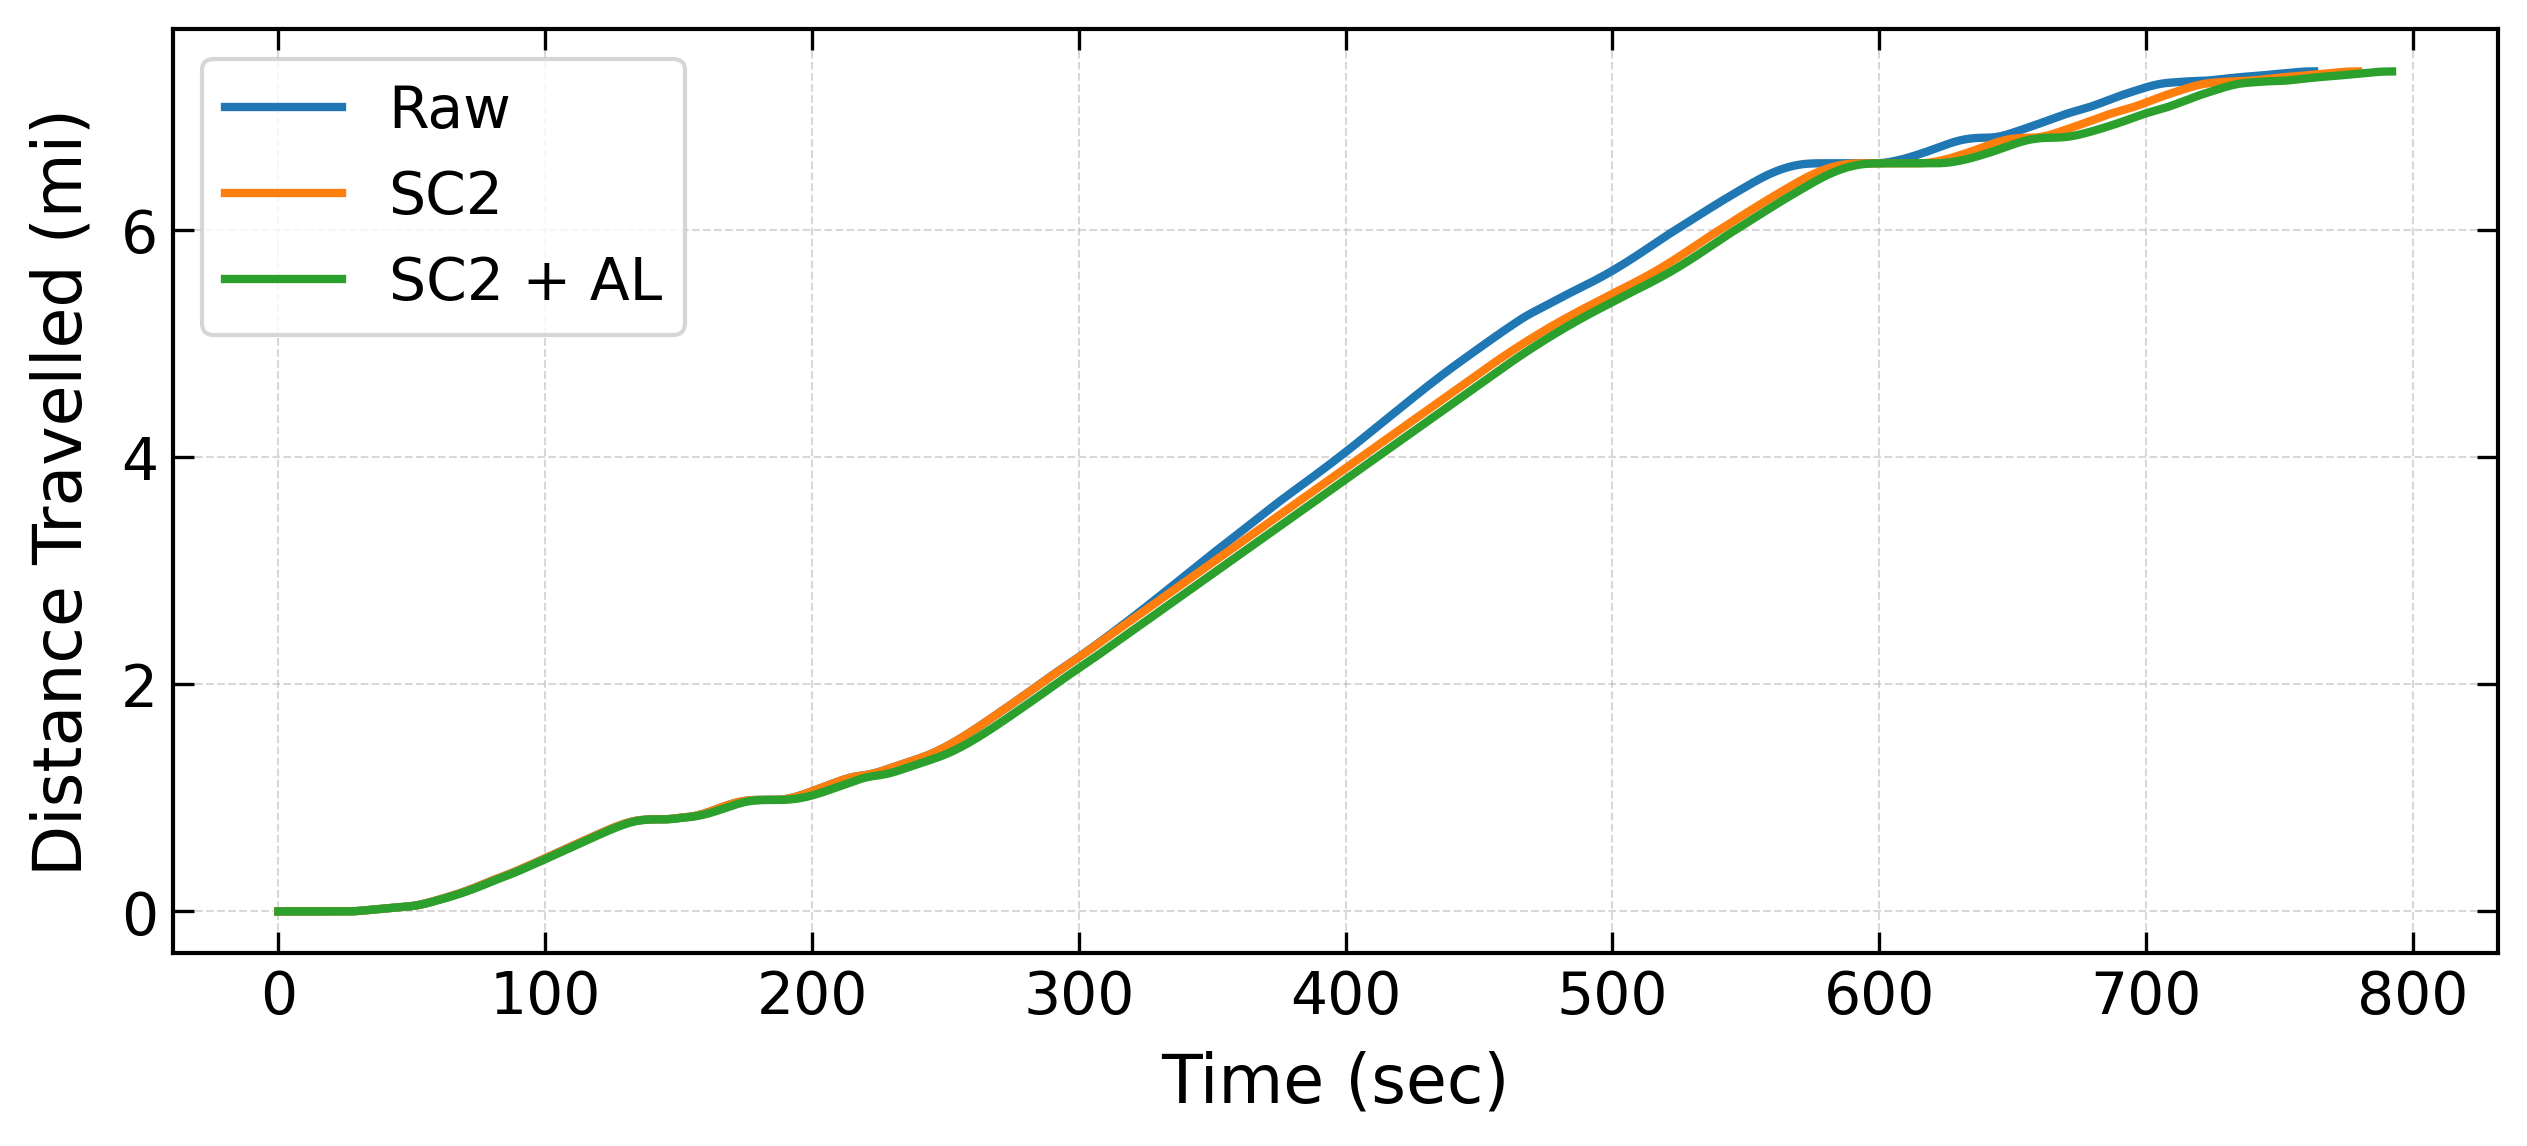

Original Distance: 7.3960060542159605
Distance after adjustment 1: 7.396006054215943
Distance after adjustment 2: 7.39565875159396


In [67]:
plt.figure(figsize=(10,4))
plt.plot(traj_og.time_s, dist_list, label='Raw')
# plt.plot(traj_adj.time_s, adjusted_dist_list, color='green', label='SC2')
plt.plot(traj_adj.time_s, adjusted_dist_list, label='SC2')
# plt.plot(traj_adj2.time_s, adjusted_dist_list2, color='red', label='Speed Limit Adjusted Speed 2')
plt.plot(traj_final1.time_s, final1_dist_list, label='SC2 + AL')

plt.xlabel('Time (sec)')
plt.ylabel('Distance Travelled (mi)')
plt.grid(True, which='major', axis='both', color='#b3b3b3', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.grid()
plt.legend()
plt.savefig('./figures/og_vs_adj_vs_final_dist_coast_new.png')
plt.show()


print(f'Original Distance: {dist_list[-1]}\nDistance after adjustment 1: {adjusted_dist_list[-1]}\nDistance after adjustment 2: {final1_dist_list[-1]}')

In [72]:
# start = 150
# end = 197
start = 0
end = len(traj_final1.speed_mph)

plt.figure(figsize=[10,4])

p = plt.plot(traj_og.time_s, [speed*1 for speed in traj_og.speed_mph], label='Raw')

# plt.plot(traj_adj.time_s, traj_adj.speed_mph, color='green',label='SC2')
p = plt.plot(traj_adj.time_s, traj_adj.speed_mph, label='SC1')

# plt.plot(traj_final1.time_s, traj_final1.speed_mph, label='SC1 + AC')
# plt.plot(traj_adj2.time_s, traj_adj2.speed_mph, label='Compliant (old coasting)')
plt.plot(traj_adj.time_s, traj_adj.speed_limit_mph, '-.', color='#D84A05', label='Limit')
plt.xlabel('Time (sec)')
plt.ylabel('Speed (mph)')

plt.legend(loc='upper right')
plt.xlim((start, end))
plt.ylim((min([speed*1-5 for speed in traj_og.speed_mph]), max([speed*1+10 for speed in traj_og.speed_mph])))
plt.grid(True, which='major', axis='both', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.show()
plt.savefig(f'./figures/og_vs_adj.png')




plt.figure(figsize=[10,4])

p = plt.plot(traj_og.time_s, [speed*1 for speed in traj_og.speed_mph], label='Raw')

# plt.plot(traj_adj.time_s, traj_adj.speed_mph, color='green',label='SC2')
p = plt.plot(traj_adj.time_s, traj_adj.speed_mph, label='SC1')

# plt.plot(traj_final1.time_s, traj_final1.speed_mph, label='SC1 + AC')
# plt.plot(traj_adj2.time_s, traj_adj2.speed_mph, label='Compliant (old coasting)')
plt.plot(traj_adj.time_s, traj_adj.speed_limit_mph, '-.', color='#D84A05', label='Limit')
plt.plot(traj_final1.time_s, traj_final1.speed_mph, label='SC1 + AL')

plt.xlabel('Time (sec)')
plt.ylabel('Speed (mph)')

plt.legend(loc='upper right')
plt.xlim((start, end))
plt.ylim((min([speed*1-5 for speed in traj_og.speed_mph]), max([speed*1+10 for speed in traj_og.speed_mph])))
plt.grid(True, which='major', axis='both', linestyle='--', linewidth=0.5, alpha=0.5)
# plt.show()
plt.savefig(f'./figures/adj_vs_final.png')






# plt.grid()
# plt.show()
# plt.figure(figsize=[10,3])
# plt.plot(traj_og.time_s, sim_drive_post_og.fc_kw_out_ach, label='Original')
# # plt.plot(traj_adj.time_s, sim_drive2.fc_kw_out_ach, label='SC2', color=(p[0].get_color()))
# plt.plot(traj_adj.time_s, sim_drive_post_adj.fc_kw_out_ach, label='SC1')
# plt.plot(traj_final1.time_s, sim_drive_post_final.fc_kw_out_ach, label='SC1 + AC')

# plt.xlabel('Time (sec)')

# plt.ylabel('Engine Power (kW)')
# plt.xlim((start,end))
# plt.ylim((min(min(sim_drive_post_og.fc_kw_out_ach[start:end]), min(sim_drive_post_adj.fc_kw_out_ach[start:end]))-5, max(max(sim_drive_post_og.fc_kw_out_ach[start:end]), max(sim_drive_post_adj.fc_kw_out_ach[start:end]))+5))
# plt.legend()
# plt.xlabel('Time (sec)')

In [310]:
type(final1_seconds), type(final1_speeds), type(adjusted_speed_limit), type(adjusted_elevation)

(numpy.ndarray, numpy.ndarray, list, list)